Real-Time CCTV AI Analytics & Deployment System
What will the system do?
Imagine a CCTV camera monitoring a parking area.

Your system will:
- Detect people and vehicles in video.
- Draw bounding boxes around detected objects.
- Assign tracking IDs to objects across consecutive frames.
- Count vehicles and people as they cross a designated line.
- Generate events, such as a vehicle entering a monitored area.
- Provide an API for retrieving events and system status.
- Monitor FPS, latency, GPU utilization, and errors.
- Handle video stream interruptions and recover where possible.
We'll build these features incrementally, testing each component before moving to the next.

### The complete system architecture

              INPUT SOURCE
                   |
          +--------+--------+
          |                 |
      MP4 Video        RTSP Camera
          |                 |
          +--------+--------+
                   |
          OpenCV / FFmpeg
                   |
             Video Frames
                   |
          Preprocessing
                   |
          YOLO Object Detection
                   |
          +--------+--------+
          |                 |
      Person Boxes     Vehicle Boxes
          |                 |
          +--------+--------+
                   |
            ByteTrack
          Tracking IDs
                   |
          Counting / Event Logic
                   |
             +-----+------+
             |            |
          FastAPI      Monitoring
             |
          PostgreSQL
             |
       Dashboard / Reports

In [1]:
import torch
import ultralytics
import cv2
import numpy as np

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.5.1+cu121
Ultralytics: 8.4.191
OpenCV: 4.12.0
NumPy: 2.2.6
CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


In [2]:
from ultralytics import YOLO
import torch

# Load a pretrained lightweight YOLO model
model = YOLO("yolo11n.pt")

# Run inference on a sample image
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    device=0,
    conf=0.35,
    save=True
)

print("\nInference completed successfully!")
print("GPU:", torch.cuda.get_device_name(0))
print("Detections:", len(results[0].boxes))
print("Saved output:", results[0].save_dir)


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /home/wasidkhan/bus.jpg: 640x480 4 persons, 1 bus, 6.5ms
Speed: 31.9ms preprocess, 6.5ms inference, 12.1ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /home/wasidkhan/runs/detect/predict-2

Inference completed successfully!
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
Detections: 5
Saved output: /home/wasidkhan/runs/detect/predict-2


In [3]:
from pathlib import Path
from collections import Counter

# Dataset root
DATASET_ROOT = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/dataset"
)

IMAGES_DIR = DATASET_ROOT / "images"
LABELS_DIR = DATASET_ROOT / "labels"

# Verify paths
print("Dataset exists:", DATASET_ROOT.exists())
print("Images directory exists:", IMAGES_DIR.exists())
print("Labels directory exists:", LABELS_DIR.exists())

# Show directory structure
print("\n--- Directory Structure ---")

for path in sorted(DATASET_ROOT.rglob("*")):
    if path.is_dir():
        print(f"[DIR]  {path.relative_to(DATASET_ROOT)}")
    elif path.is_file():
        print(f"[FILE] {path.relative_to(DATASET_ROOT)}")

    # Limit displayed entries to avoid excessive output
    if path == sorted(DATASET_ROOT.rglob("*"))[100:101]:
        break

Dataset exists: True
Images directory exists: True
Labels directory exists: True

--- Directory Structure ---
[FILE] classes.txt
[FILE] data.yaml
[DIR]  images
[DIR]  images/train
[FILE] images/train/000000026154.jpg
[FILE] images/train/000000026511.jpg
[FILE] images/train/000000027462.jpg
[FILE] images/train/000000027473.jpg
[FILE] images/train/000000027518.jpg
[FILE] images/train/000000028065.jpg
[FILE] images/train/000000028124.jpg
[FILE] images/train/000000028465.jpg
[FILE] images/train/000000028544.jpg
[FILE] images/train/000000028677.jpg
[FILE] images/train/000000028787.jpg
[FILE] images/train/000000029242.jpg
[FILE] images/train/000000029660.jpg
[FILE] images/train/000000029856.jpg
[FILE] images/train/000000029969.jpg
[FILE] images/train/000000030131.jpg
[FILE] images/train/000000030634.jpg
[FILE] images/train/000000030884.jpg
[FILE] images/train/000000031046.jpg
[FILE] images/train/000000031122.jpg
[FILE] images/train/000000031315.jpg
[FILE] images/train/000000031541.jpg
[FILE]

In [4]:
from pathlib import Path

root = Path("/home/wasidkhan/yolo-person-vehicle-dataset/dataset")

for folder in sorted(root.rglob("*")):
    if folder.is_dir():
        files = list(folder.iterdir())
        print(
            f"{folder.relative_to(root) or '.'}/ "
            f"({len(files)} immediate entries)"
        )

print("\nConfiguration files:")

for name in ["data.yaml", "data.yml", "dataset.yaml"]:
    for file in root.rglob(name):
        print(file)

images/ (2 immediate entries)
images/train/ (1600 immediate entries)
images/val/ (400 immediate entries)
labels/ (4 immediate entries)
labels/train/ (1600 immediate entries)
labels/val/ (400 immediate entries)

Configuration files:
/home/wasidkhan/yolo-person-vehicle-dataset/dataset/data.yaml


In [5]:
from pathlib import Path
from collections import Counter

root = Path("/home/wasidkhan/yolo-person-vehicle-dataset/dataset")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

labels = list(root.rglob("*.txt"))

print("Total images:", len(images))
print("Total text label files:", len(labels))

print("\nImage distribution by folder:")

image_counts = Counter(str(p.parent.relative_to(root)) for p in images)

for folder, count in sorted(image_counts.items()):
    print(f"{folder}: {count}")

print("\nLabel distribution by folder:")

label_counts = Counter(str(p.parent.relative_to(root)) for p in labels)

for folder, count in sorted(label_counts.items()):
    print(f"{folder}: {count}")

Total images: 2000
Total text label files: 2001

Image distribution by folder:
images/train: 1600
images/val: 400

Label distribution by folder:
.: 1
labels/train: 1600
labels/val: 400


In [6]:
# Inspect the extra file and annotation labels

ROOT = Path("/home/wasidkhan/yolo-person-vehicle-dataset/dataset")

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# 1. Inspect the extra root-level text file
print("ROOT-LEVEL TEXT FILES")
for path in ROOT.glob("*.txt"):
    print(f"\nFile: {path.name}")
    print(path.read_text(errors="replace")[:1000])

# 2. Check that every image has a corresponding label
print("\nIMAGE-LABEL MATCHING")

for split in ["train", "val"]:
    image_dir = ROOT / "images" / split
    label_dir = ROOT / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]

    labels = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    missing_labels = sorted(image_stems - label_stems)
    orphan_labels = sorted(label_stems - image_stems)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images without label files:", len(missing_labels))
    print("Labels without matching images:", len(orphan_labels))

    if missing_labels:
        print("Missing label examples:", missing_labels[:5])

    if orphan_labels:
        print("Orphan label examples:", orphan_labels[:5])

# 3. Inspect class IDs and annotation validity
class_counts = Counter()
invalid_lines = []
empty_label_files = []
total_boxes = 0

for split in ["train", "val"]:
    label_dir = ROOT / "labels" / split

    for label_path in label_dir.glob("*.txt"):
        lines = label_path.read_text().splitlines()

        if not any(line.strip() for line in lines):
            empty_label_files.append(str(label_path))
            continue

        for line_number, line in enumerate(lines, start=1):
            if not line.strip():
                continue

            parts = line.split()

            try:
                values = [float(x) for x in parts]

                # Standard YOLO detection format has five values.
                if len(values) != 5:
                    raise ValueError(
                        f"Expected 5 values, found {len(values)}"
                    )

                class_value, xc, yc, w, h = values

                if not class_value.is_integer() or class_value < 0:
                    raise ValueError("Invalid class ID")

                if not all(0 <= v <= 1 for v in [xc, yc, w, h]):
                    raise ValueError("Coordinates outside [0, 1]")

                if w <= 0 or h <= 0:
                    raise ValueError("Non-positive box width/height")

                class_counts[int(class_value)] += 1
                total_boxes += 1

            except (ValueError, OverflowError) as exc:
                invalid_lines.append(
                    (str(label_path), line_number, str(exc), line)
                )

print("\nANNOTATION SUMMARY")
print("Total valid bounding boxes:", total_boxes)
print("Bounding boxes by class ID:", dict(sorted(class_counts.items())))
print("Empty label files:", len(empty_label_files))
print("Invalid annotation lines:", len(invalid_lines))

if invalid_lines:
    print("\nFirst 10 invalid lines:")
    for item in invalid_lines[:10]:
        print(item)

if empty_label_files:
    print("\nFirst 5 empty label files:")
    for path in empty_label_files[:5]:
        print(path)

ROOT-LEVEL TEXT FILES

File: classes.txt
person
vehicle


IMAGE-LABEL MATCHING

TRAIN
Images: 1600
Label files: 1600
Images without label files: 0
Labels without matching images: 0

VAL
Images: 400
Label files: 400
Images without label files: 0
Labels without matching images: 0

ANNOTATION SUMMARY
Total valid bounding boxes: 4041
Bounding boxes by class ID: {0: 2386, 1: 1655}
Empty label files: 0
Invalid annotation lines: 0


In [7]:
# YOLO needs a configuration file that tells it where the training and validation images are and what the classes are called.
# data.yaml doesn't contain the images or labels. It tells YOLO where to find them.
# YOLO automatically looks for corresponding labels in labels/train/ and labels/val/, following its standard directory convention.


dataset_root = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/dataset"
)

yaml_content = """\
path: /home/wasidkhan/yolo-person-vehicle-dataset/dataset
train: images/train
val: images/val

names:
  0: person
  1: vehicle
"""

yaml_path = dataset_root / "data.yaml"
yaml_path.write_text(yaml_content)

print("Created:", yaml_path)
print(yaml_path.read_text())

Created: /home/wasidkhan/yolo-person-vehicle-dataset/dataset/data.yaml
path: /home/wasidkhan/yolo-person-vehicle-dataset/dataset
train: images/train
val: images/val

names:
  0: person
  1: vehicle



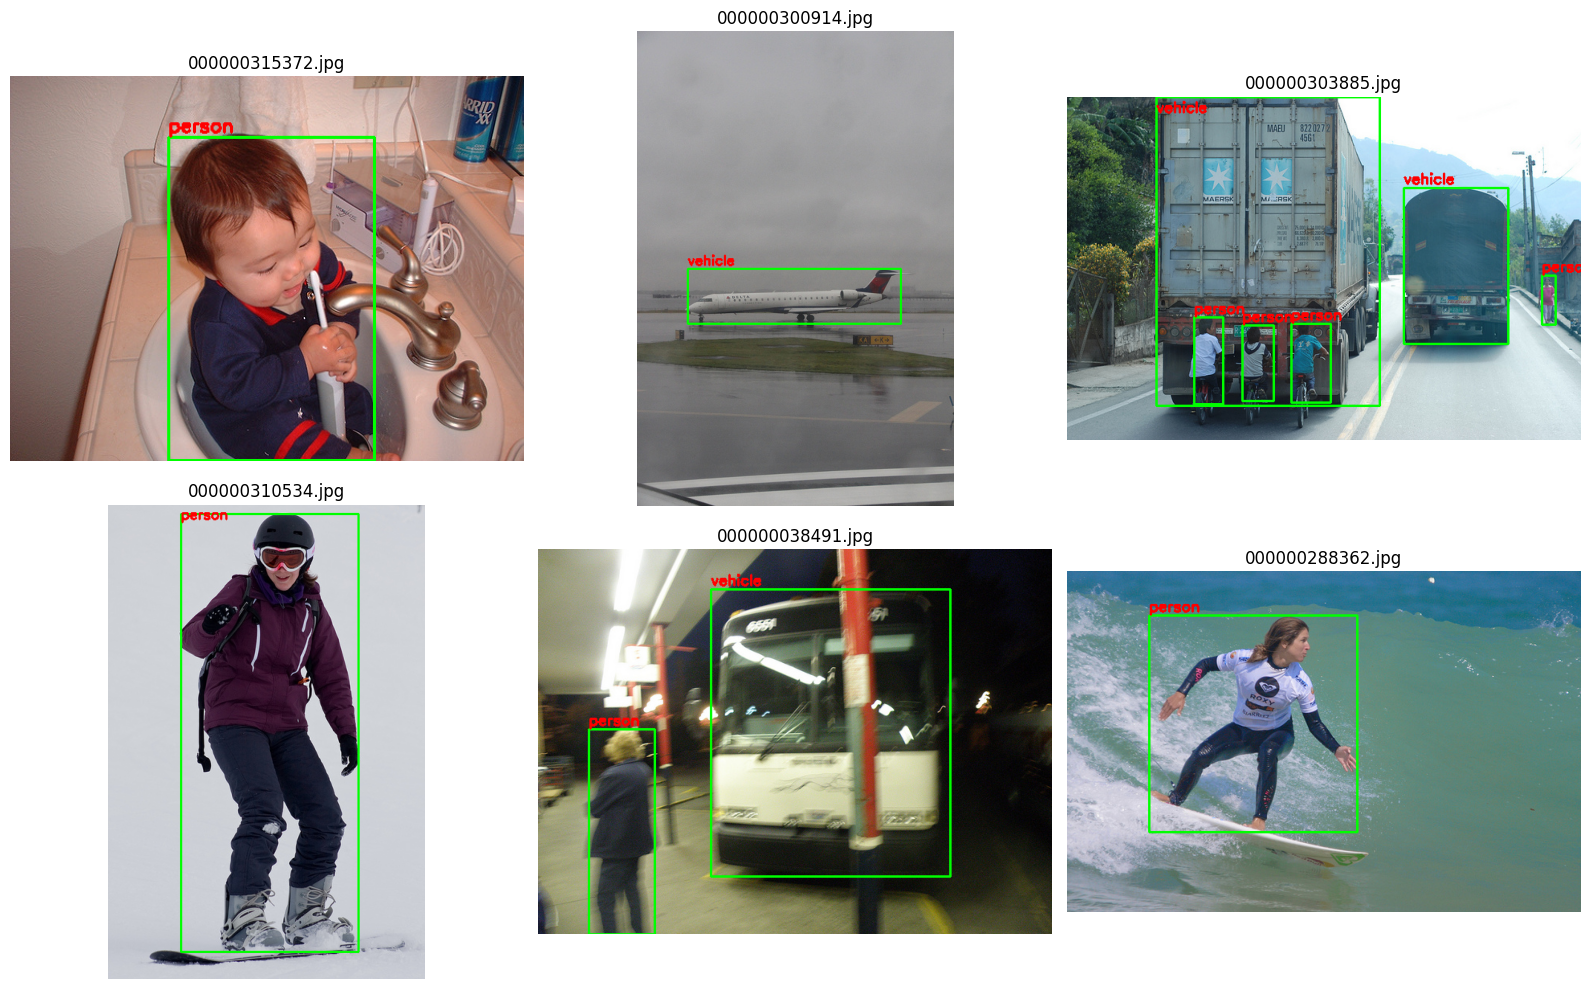

In [8]:
# visualize annotations


import random
import cv2
import matplotlib.pyplot as plt

ROOT = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/dataset"
)

IMAGE_DIR = ROOT / "images" / "train"
LABEL_DIR = ROOT / "labels" / "train"

CLASS_NAMES = {
    0: "person",
    1: "vehicle"
}

image_paths = [
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

random.seed(42)
selected_images = random.sample(image_paths, min(6, len(image_paths)))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, selected_images):
    image = cv2.imread(str(image_path))

    if image is None:
        ax.set_title(f"Could not read {image_path.name}")
        ax.axis("off")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()

            if len(parts) != 5:
                continue

            class_id, xc, yc, bw, bh = map(float, parts)

            x1 = int((xc - bw / 2) * width)
            y1 = int((yc - bh / 2) * height)
            x2 = int((xc + bw / 2) * width)
            y2 = int((yc + bh / 2) * height)

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            name = CLASS_NAMES.get(int(class_id), f"class_{int(class_id)}")

            cv2.putText(
                image,
                name,
                (x1, max(20, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 0, 0),
                2
            )

    ax.imshow(image)
    ax.set_title(image_path.name)
    ax.axis("off")

for ax in axes[len(selected_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Train YOLO11n

In [9]:
from ultralytics import YOLO
import torch

assert torch.cuda.is_available(), "CUDA GPU is not available!"

model = YOLO("yolo11n.pt")

results = model.train(
    data="/home/wasidkhan/yolo-person-vehicle-dataset/dataset/data.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    project="/home/wasidkhan/yolo-person-vehicle-dataset/runs",
    name="person_vehicle_yolo11n",
    seed=42,
    plots=True
)

print("Training completed!")

Ultralytics 8.4.191 🚀 Python-3.11.15 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 5797MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/wasidkhan/yolo-person-vehicle-dataset/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pers

## Evaluate the trained model

In [10]:
from ultralytics import YOLO

best_model = YOLO(
    "/home/wasidkhan/yolo-person-vehicle-dataset/runs/person_vehicle_yolo11n/weights/best.pt"
)

metrics = best_model.val(
    data="/home/wasidkhan/yolo-person-vehicle-dataset/dataset/data.yaml",
    imgsz=640,
    batch=8,
    device=0
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.191 🚀 Python-3.11.15 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 5797MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4507.8±1127.4 MB/s, size: 158.3 KB)
val: Scanning /home/wasidkhan/yolo-person-vehicle-dataset/dataset/labels/val.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 152.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 15.5it/s 3.2s0.1s
                   all        400        791      0.857      0.809      0.879      0.647
                person        264        467       0.86      0.788      0.886       0.61
               vehicle        208        324      0.853       0.83      0.871      0.683
Speed: 0.5ms preprocess, 3.6ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /home/wasidkhan/runs/detect/val-3
mAP50: 0.8788144479100979

In [11]:

# Load the model trained on our person-vehicle dataset
best_model = YOLO(
    "/home/wasidkhan/yolo-person-vehicle-dataset/runs/person_vehicle_yolo11n/weights/best.pt"
)

# Evaluate it on the validation dataset
metrics = best_model.val(
    data="/home/wasidkhan/yolo-person-vehicle-dataset/dataset/data.yaml",
    imgsz=640,
    batch=8,
    device=0
)

print("\n--- Fine-tuned Model Results ---")
print(f"mAP50:       {metrics.box.map50:.4f}")
print(f"mAP50-95:    {metrics.box.map:.4f}")
print(f"Precision:   {metrics.box.mp:.4f}")
print(f"Recall:      {metrics.box.mr:.4f}")

Ultralytics 8.4.191 🚀 Python-3.11.15 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 5797MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4674.4±396.0 MB/s, size: 236.5 KB)
val: Scanning /home/wasidkhan/yolo-person-vehicle-dataset/dataset/labels/val.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 119.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 18.0it/s 2.8s0.0s
                   all        400        791      0.857      0.809      0.879      0.647
                person        264        467       0.86      0.788      0.886       0.61
               vehicle        208        324      0.853       0.83      0.871      0.683
Speed: 0.5ms preprocess, 2.3ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /home/wasidkhan/runs/detect/val-4

--- Fine-tuned Model Resu

In [12]:
from pathlib import Path

checkpoint = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/runs/person_vehicle_yolo11n/weights/best.pt"
)

print("Checkpoint exists:", checkpoint.exists())

Checkpoint exists: True


## Visualize predictions

In [13]:
from pathlib import Path
from IPython.display import display, Image

dataset_dir = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/dataset"
)

results = best_model.predict(
    source=str(dataset_dir / "images" / "val"),
    imgsz=640,
    conf=0.35,
    device=0,
    save=True,
    project="/home/wasidkhan/yolo-person-vehicle-dataset/runs",
    name="validation_predictions"
)

print("Predictions saved to:")
print("/home/wasidkhan/yolo-person-vehicle-dataset/runs/validation_predictions")


image 1/400 /home/wasidkhan/yolo-person-vehicle-dataset/dataset/images/val/000000028302.jpg: 448x640 1 vehicle, 8.4ms
image 2/400 /home/wasidkhan/yolo-person-vehicle-dataset/dataset/images/val/000000029396.jpg: 480x640 1 person, 1 vehicle, 60.4ms
image 3/400 /home/wasidkhan/yolo-person-vehicle-dataset/dataset/images/val/000000029743.jpg: 480x640 1 vehicle, 9.0ms
image 4/400 /home/wasidkhan/yolo-person-vehicle-dataset/dataset/images/val/000000030291.jpg: 640x640 1 vehicle, 8.4ms
image 5/400 /home/wasidkhan/yolo-person-vehicle-dataset/dataset/images/val/000000030858.jpg: 480x640 2 vehicles, 9.1ms
image 6/400 /home/wasidkhan/yolo-person-vehicle-dataset/dataset/images/val/000000035531.jpg: 448x640 1 person, 4 vehicles, 9.6ms
image 7/400 /home/wasidkhan/yolo-person-vehicle-dataset/dataset/images/val/000000035824.jpg: 480x640 1 vehicle, 9.1ms
image 8/400 /home/wasidkhan/yolo-person-vehicle-dataset/dataset/images/val/000000036319.jpg: 448x640 3 vehicles, 9.2ms
image 9/400 /home/wasidkhan/yol

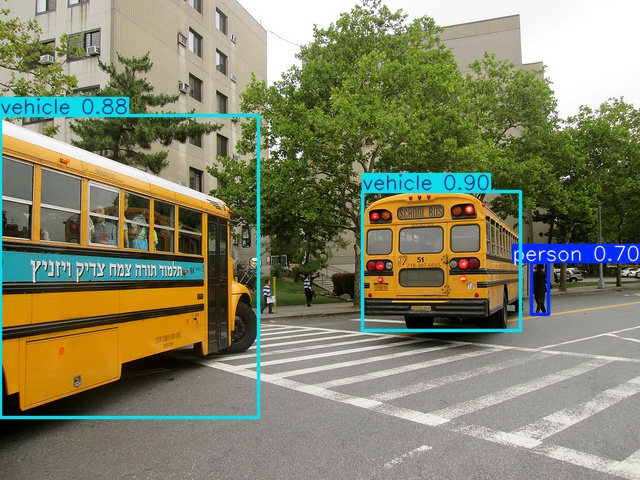

In [14]:
# To display one saved image directly in your notebook:

prediction_dir = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/runs/validation_predictions"
)

image_files = [
    p for p in prediction_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

if image_files:
    display(Image(filename=str(image_files[0])))
else:
    print("No saved images found.")

## we'll run it on a video file and measure its actual FPS

In [15]:
from pathlib import Path

VIDEO_DIR = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/videos"
)
VIDEO_DIR.mkdir(parents=True, exist_ok=True)

print("Video folder:", VIDEO_DIR)

Video folder: /home/wasidkhan/yolo-person-vehicle-dataset/videos


## Run the model on video

In [16]:

# Load our fine-tuned model
model = YOLO(
    "/home/wasidkhan/yolo-person-vehicle-dataset/runs/person_vehicle_yolo11n/weights/best.pt"
)

# Input video
video_path = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/videos/cctv_test.mp4"
)

assert video_path.exists(), f"Video not found: {video_path}"

# Run detection and save the annotated video
results = model.predict(
    source=str(video_path),
    imgsz=640,
    conf=0.35,
    device=0,
    save=True,
    project="/home/wasidkhan/yolo-person-vehicle-dataset/runs",
    name="video_detection"
)

print("Video processing completed.")
print("Check the video_detection folder for the output.")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/136) /home/wasidkhan/yolo-person-vehicle-dataset/videos/cctv_test.mp4: 384x640 1 person, 6 vehicles, 9.2ms
video 1/1 (frame 2/136) /home/wasidkhan/yolo-person-vehicle-dataset/videos/cctv_test.mp4: 384x640 1 person, 6 vehicles, 10.1ms
video 1/1 (frame 3/136) /home/wasidkhan/yolo-person-vehicle-dataset/videos/cctv_test.mp4: 384x640 1 person, 6 vehicles, 9.1ms
video 1/1 (frame 4/136) /home/wasidkhan/yolo-person-vehicle-dataset/videos/cctv_

In [17]:
MODEL_PATH = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/runs/person_vehicle_yolo11n/weights/best.pt"
)

VIDEO_PATH = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/videos/cctv_test.mp4"
)

print("Model exists:", MODEL_PATH.exists())
print("Video exists:", VIDEO_PATH.exists())

Model exists: True
Video exists: True


## applying bytetrack on video

In [20]:
# Load our fine-tuned person/vehicle detector
model = YOLO(
    "/home/wasidkhan/yolo-person-vehicle-dataset/runs/person_vehicle_yolo11n/weights/best.pt"
)

video_path = (
    "/home/wasidkhan/yolo-person-vehicle-dataset/videos/cctv_test2.mp4"
)

# Detect and track objects
results = model.track(
    source=video_path,
    tracker="bytetrack.yaml",  # bytetrack
    imgsz=640,
    conf=0.25,
    iou=0.5,
    device=0,
    persist=True,
    stream=True,
    save=True,
    show=False,
    project="/home/wasidkhan/yolo-person-vehicle-dataset/runs",
    name="bytetrack_output"
)

print("ByteTrack processing completed!")
print(
    "Output folder:",
    "/home/wasidkhan/yolo-person-vehicle-dataset/runs/bytetrack_output"
)

ByteTrack processing completed!
Output folder: /home/wasidkhan/yolo-person-vehicle-dataset/runs/bytetrack_output


## Vehicle Counting with YOLO11 + ByteTrack.

In [29]:

from ultralytics import YOLO
from pathlib import Path
import cv2

# ==================================================
# 1. PATHS
# ==================================================

MODEL_PATH = (
    "/home/wasidkhan/yolo-person-vehicle-dataset/"
    "runs/person_vehicle_yolo11n/weights/best.pt"
)

VIDEO_PATH = (
    "/home/wasidkhan/yolo-person-vehicle-dataset/"
    "videos/cctv_vehiclecrossing.mp4"
)

OUTPUT_DIR = Path(
    "/home/wasidkhan/yolo-person-vehicle-dataset/runs"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "vehicle_counting_multiline.mp4"


# ==================================================
# 2. CONFIGURATION
# ==================================================

# Enable either or both counting lines.
ENABLE_HORIZONTAL_LINE = True
ENABLE_VERTICAL_LINE = True

# Line positions as proportions of the frame dimensions.
# Adjust these values according to your video.
HORIZONTAL_LINE_POSITION = 0.55
VERTICAL_LINE_POSITION = 0.50

# Classes in our custom dataset:
# 0 = person
# 1 = vehicle


# ==================================================
# 3. LOAD MODEL AND VIDEO
# ==================================================

model = YOLO(MODEL_PATH)

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if fps <= 0:
    fps = 25.0

print(f"Video resolution: {width} x {height}")
print(f"Video FPS: {fps:.2f}")
print(f"Total frames: {total_frames}")


# ==================================================
# 4. OUTPUT VIDEO WRITER
# ==================================================

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    str(OUTPUT_PATH),
    fourcc,
    fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create output video.")


# ==================================================
# 5. COUNTING LINES
# ==================================================

# Horizontal line: objects crossing vertically.
HORIZONTAL_Y = int(height * HORIZONTAL_LINE_POSITION)

# Vertical line: objects crossing horizontally.
VERTICAL_X = int(width * VERTICAL_LINE_POSITION)


# ==================================================
# 6. TRACKING AND COUNTING STATE
# ==================================================

# Previous reference point for each tracked object.
previous_positions = {}

# Remember counted IDs to prevent duplicate counting.
counted_vehicle_ids = set()
counted_person_ids = set()

vehicle_count = 0
person_count = 0

frame_number = 0


# ==================================================
# 7. PROCESS VIDEO
# ==================================================

try:
    while True:

        success, frame = cap.read()

        if not success:
            break

        frame_number += 1

        # YOLO detection + ByteTrack tracking.
        result = model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            imgsz=640,
            conf=0.25,
            device=0,
            verbose=False
        )[0]

        # ------------------------------------------
        # Draw counting lines
        # ------------------------------------------

        if ENABLE_HORIZONTAL_LINE:
            cv2.line(
                frame,
                (0, HORIZONTAL_Y),
                (width, HORIZONTAL_Y),
                (0, 255, 255),
                2
            )

            cv2.putText(
                frame,
                "Horizontal counting line",
                (20, max(25, HORIZONTAL_Y - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 255),
                2
            )

        if ENABLE_VERTICAL_LINE:
            cv2.line(
                frame,
                (VERTICAL_X, 0),
                (VERTICAL_X, height),
                (255, 0, 255),
                2
            )

            cv2.putText(
                frame,
                "Vertical line",
                (min(VERTICAL_X + 8, width - 180), 30),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (255, 0, 255),
                2
            )

        # ------------------------------------------
        # Process tracked detections
        # ------------------------------------------

        if (
            result.boxes is not None
            and result.boxes.id is not None
        ):

            boxes = result.boxes.xyxy.cpu().numpy()
            track_ids = result.boxes.id.int().cpu().tolist()
            class_ids = result.boxes.cls.int().cpu().tolist()

            for box, track_id, class_id in zip(
                boxes, track_ids, class_ids
            ):

                x1, y1, x2, y2 = map(int, box)

                # Use bottom-center as the reference point.
                center_x = (x1 + x2) // 2
                bottom_y = y2

                if class_id == 1:
                    label = "Vehicle"
                    color = (0, 255, 0)
                    counted_ids = counted_vehicle_ids

                elif class_id == 0:
                    label = "Person"
                    color = (255, 100, 0)
                    counted_ids = counted_person_ids

                else:
                    continue

                # Draw bounding box.
                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    color,
                    2
                )

                # Draw reference point.
                cv2.circle(
                    frame,
                    (center_x, bottom_y),
                    5,
                    (0, 0, 255),
                    -1
                )

                # Draw class and tracking ID.
                cv2.putText(
                    frame,
                    f"{label} ID:{track_id}",
                    (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.55,
                    color,
                    2
                )

                # Key positions by class AND tracking ID.
                object_key = (class_id, track_id)

                previous_point = previous_positions.get(object_key)

                if previous_point is not None:

                    previous_x, previous_y = previous_point

                    # ----------------------------------
                    # Horizontal-line crossing
                    # ----------------------------------

                    crossed_horizontal = (
                        ENABLE_HORIZONTAL_LINE
                        and (
                            previous_y < HORIZONTAL_Y <= bottom_y
                            or
                            previous_y > HORIZONTAL_Y >= bottom_y
                        )
                    )

                    # ----------------------------------
                    # Vertical-line crossing
                    # ----------------------------------

                    crossed_vertical = (
                        ENABLE_VERTICAL_LINE
                        and (
                            previous_x < VERTICAL_X <= center_x
                            or
                            previous_x > VERTICAL_X >= center_x
                        )
                    )

                    crossed_any_line = (
                        crossed_horizontal or crossed_vertical
                    )

                    # Count each tracked ID once, even if it
                    # crosses both lines during the video.
                    if (
                        crossed_any_line
                        and track_id not in counted_ids
                    ):

                        counted_ids.add(track_id)

                        if class_id == 1:
                            vehicle_count += 1

                            print(
                                f"Vehicle ID {track_id} crossed a line. "
                                f"Vehicle total: {vehicle_count}"
                            )

                        elif class_id == 0:
                            person_count += 1

                            print(
                                f"Person ID {track_id} crossed a line. "
                                f"People total: {person_count}"
                            )

                # Update the object's previous position.
                previous_positions[object_key] = (
                    center_x,
                    bottom_y
                )

        # ------------------------------------------
        # Display counters
        # ------------------------------------------

        cv2.rectangle(
            frame,
            (10, 10),
            (370, 95),
            (0, 0, 0),
            -1
        )

        cv2.putText(
            frame,
            f"Vehicles counted: {vehicle_count}",
            (20, 42),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.70,
            (0, 255, 0),
            2
        )

        cv2.putText(
            frame,
            f"People counted: {person_count}",
            (20, 76),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.70,
            (255, 180, 0),
            2
        )

        writer.write(frame)

        if frame_number % 30 == 0:
            print(
                f"Processed {frame_number}/{total_frames} frames"
            )

finally:
    cap.release()
    writer.release()


# ==================================================
# 8. FINAL RESULTS
# ==================================================

print("\nCounting completed!")
print(f"Vehicles counted: {vehicle_count}")
print(f"People counted: {person_count}")
print(f"Output video: {OUTPUT_PATH}")

Video resolution: 3840 x 2160
Video FPS: 59.94
Total frames: 1714
Processed 30/1714 frames
Processed 60/1714 frames
Processed 90/1714 frames
Processed 120/1714 frames
Processed 150/1714 frames
Processed 180/1714 frames
Vehicle ID 3 crossed a line. Vehicle total: 1
Processed 210/1714 frames
Vehicle ID 107 crossed a line. Vehicle total: 2
Processed 240/1714 frames
Processed 270/1714 frames
Vehicle ID 151 crossed a line. Vehicle total: 3
Processed 300/1714 frames
Processed 330/1714 frames
Vehicle ID 162 crossed a line. Vehicle total: 4
Processed 360/1714 frames
Processed 390/1714 frames
Processed 420/1714 frames
Processed 450/1714 frames
Vehicle ID 232 crossed a line. Vehicle total: 5
Processed 480/1714 frames
Processed 510/1714 frames
Processed 540/1714 frames
Processed 570/1714 frames
Vehicle ID 298 crossed a line. Vehicle total: 6
Processed 600/1714 frames
Processed 630/1714 frames
Processed 660/1714 frames
Processed 690/1714 frames
Vehicle ID 439 crossed a line. Vehicle total: 7
Proce

Our final project: AI-Powered CCTV Analytics
Technologies: Python, YOLO11, PyTorch, OpenCV, ByteTrack, Streamlit, Git, GitHub.
What users will be able to do
- Upload a CCTV or traffic video.
- Detect people and vehicles using your fine-tuned YOLO11n model.
- Track objects across frames using ByteTrack.
- View the annotated output video.
- See vehicle and pedestrian counts.
- Download the processed video.
- Access the application through a public deployment link.